In [5]:
import torch
from torch import nn
import pandas as pd
import matplotlib.pyplot as plt


X shape torch.Size([100, 2]) Y shape torch.Size([100, 1])
epoch   0: loss = 3031.186768
epoch  50: loss = 192.118011
epoch 100: loss = 97.740242
epoch 150: loss = 74.234467
epoch 200: loss = 62.526623
epoch 250: loss = 54.862267


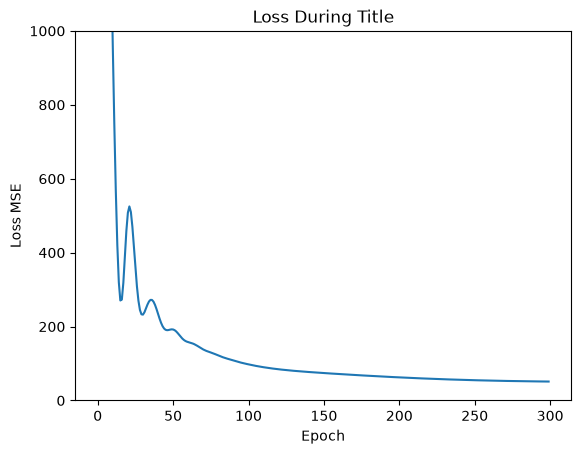

3 student hours, 2 Phone hours- 61.0 Marks


In [22]:
load_dataset = pd.read_csv("students_100.csv")
x = torch.tensor(
    load_dataset[["study_hours", "phone_hours"]].values,
    dtype = torch.float32)

y = torch.tensor(
    load_dataset[["maths"]].values,
    dtype = torch.float32)

print("X shape",x.shape, "Y shape",y.shape)
torch.manual_seed(42)
model = nn.Sequential(
    nn.Linear(2,3),
    nn.ReLU(),
    nn.Linear(3,1),
)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(),lr=0.1)

losses = []
for epoch in range(300):
    guess = model(x)
    loss = loss_fn(guess, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch %50 ==0:
        print(f"epoch {epoch:3}: loss = {loss.item():1f}")
        
plt.plot(losses)
plt.ylim(0,1000)
plt.title("Loss During Title")
plt.xlabel("Epoch")
plt.ylabel("Loss MSE")
plt.show()

with torch.no_grad():
    new_student = torch.tensor([[3,2]], dtype= torch.float32)
    print("3 student hours, 2 Phone hours-", round(model(new_student).item(),1),"Marks")
